In [1]:
import sklearn.datasets
import matplotlib.pyplot as plt
import numpy as np

Definimos com quantos cluster queremos trabalhar

In [2]:
k = 3

Vamos gerar os nossos dados aleatoriamente. Usaremos o valor de K definido anteriormente para definir a quantidade de clusters, para garantir o acerto do algoritmo. Com dados reais, nem sempre é possível saber a quantidade exata com antecedência, então pode ser necessária algumas tentativas até obter o melhor valor de K.

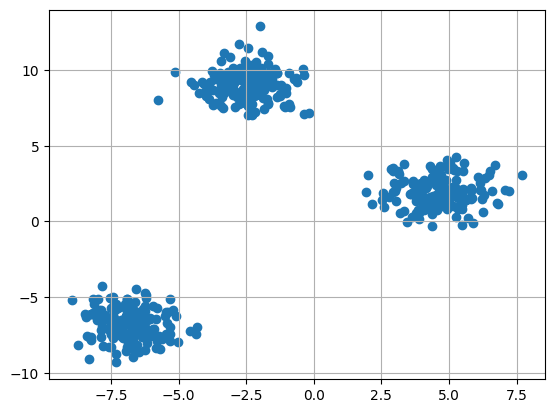

In [3]:
X,y = sklearn.datasets.make_blobs(n_samples = 500,n_features = 2,centers = k,random_state = 42)

fig = plt.figure(0)
plt.grid(True)
plt.scatter(X[:,0],X[:,1])
plt.show()

Agora, vamos gerar K pontos que serão usados para buscar o centro dos clusters.

In [4]:
clusters = {}

for idx in range(k):
    center = np.random.uniform(-3, 3, X.shape[1])
    points = []
    cluster = {
        'center' : center,
        'points' : []
    }

    clusters[idx] = cluster

clusters

{0: {'center': array([-1.86227824, -1.75191354]), 'points': []},
 1: {'center': array([-2.65334955, -1.18175853]), 'points': []},
 2: {'center': array([-1.83589905, -2.5017481 ]), 'points': []}}

Como podem ser vistos na imagem abaixo, os centros não são escolhidos como pontos existentes, mas sim pontos virtuais que serão deslocados para o centro de cada cluster

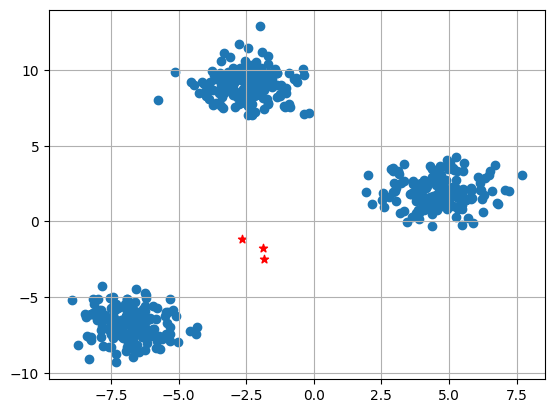

In [5]:
plt.scatter(X[:,0],X[:,1])
plt.grid(True)
for i in clusters:
    center = clusters[i]['center']
    plt.scatter(center[0],center[1],marker = '*',c = 'red')
plt.show()

In [6]:
def distance(p1,p2): #distância euclidiana
    return np.sqrt(np.sum((p1-p2)**2))

In [7]:
def assign_clusters(X, clusters):
    for idx in range(X.shape[0]):
        dist = []

        curr_x = X[idx]

        for i in range(k):
            dis = distance(curr_x,clusters[i]['center'])
            dist.append(dis)
        curr_cluster = np.argmin(dist)
        clusters[curr_cluster]['points'].append(curr_x)
    return clusters

def update_clusters(X, clusters):
    for i in range(k):
        points = np.array(clusters[i]['points'])
        if points.shape[0] > 0:
            new_center = points.mean(axis =0)
            clusters[i]['center'] = new_center

            clusters[i]['points'] = []
    return clusters

In [8]:
def pred_cluster(X, clusters):
    pred = []
    for i in range(X.shape[0]):
        dist = []
        for j in range(k):
            dist.append(distance(X[i],clusters[j]['center']))
        pred.append(np.argmin(dist))
    return pred

Finalmente, juntamos nossas funções e fazemos o treinamento do modelo e as predições

In [9]:

max_iters = 100

for _ in range(max_iters):
    old_centers = [clusters[i]['center'].copy() for i in range(k)]

    clusters = assign_clusters(X, clusters)
    clusters = update_clusters(X, clusters)

    new_centers = [clusters[i]['center'] for i in range(k)]

    if np.allclose(old_centers, new_centers):
        break

pred = pred_cluster(X, clusters)

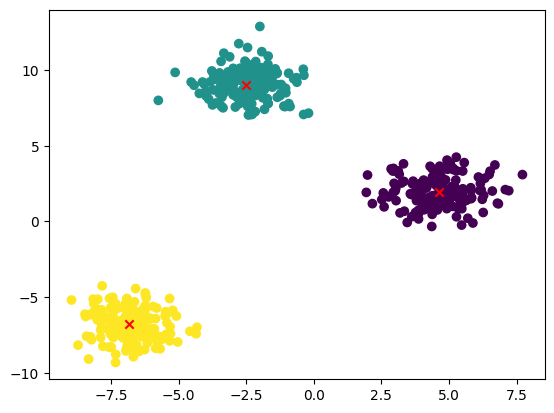

In [10]:
plt.scatter(X[:,0],X[:,1],c = pred)
for i in clusters:
    center = clusters[i]['center']
    plt.scatter(center[0],center[1],marker = 'x',c = 'red')
plt.show()

A partir do modelo pronto, podemos definir um ponto aleatório e predizer a qual cluster ele vai fazer parte

In [11]:
novo_ponto = np.array([[-5, -5]])

# Predizer o cluster do novo ponto
cluster_novo = pred_cluster(novo_ponto, clusters)[0]

print(cluster_novo)

2


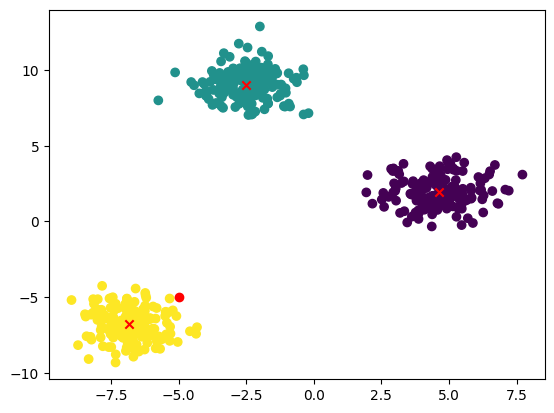

In [12]:
plt.scatter(X[:,0],X[:,1],c = pred)
for i in clusters:
    center = clusters[i]['center']
    plt.scatter(center[0],center[1],marker = 'x',c = 'red')
plt.scatter(novo_ponto[0,0], novo_ponto[0,1], marker = "o", c='red')
plt.show()